# 1. Policy experiment: classic BehaviorSpace analysis

This notebook uses **only the experiment table**, without positions or spatial clustering tests. It compares residential similarity, required relocation, and settling across the imposed rules.

**Design:** same-group minima 10, 15, …, 90%; 30 repetitions each; expected occupancy 85%; stop when no citizen must relocate or at 1,000 cycles. Cycles have no calendar interpretation. `requirement-met?` is an administrative state, not personal happiness or political support.

**Reproducibility note:** the supplied CSV has 30 repetitions per threshold, but the uploaded model's saved experiment configuration says `repetitions="1"` and setup `setup`. Set repetitions to 30 and explicitly use `set-topology false false` before `setup` when reproducing the bounded exercise. Original simulation seeds are not exported. Source URLs use main and may change; the package preserves the downloaded table and model.

**Colab:** upload this notebook and run it. Data load directly from the public course repository. If needed, install the packages listed below. Figures and results are already embedded.

Packages: `pandas numpy matplotlib scipy` (plus `ipython` for display).

## 1. Load and verify the final experiment
One row is one simulation run. Runs, not citizens or ticks, are the independent replications assumed for uncertainty intervals.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t

BASE_URL='https://raw.githubusercontent.com/DACSS-Complexity/s6_From_Micromotives_to_Macrobehavior/main/exercise/'
results=pd.read_csv(BASE_URL+'policy-relocation-table.csv',skiprows=6).rename(columns={
    '[run number]':'run','%-similar-required':'minimum','[step]':'step',
    'calculate-percent-similar':'similar',
    'calculate-percent-required-to-relocate':'relocate',
    'all? citizens [requirement-met?]':'met'})

## 2. Summarize the outcomes
Similarity is the pooled same-group neighbor share, not a binary segregation classification. This table alone lacks actual group counts for a composition-adjusted random-mixing benchmark; the spatial notebook supplies that comparison.

SD measures run-to-run variation. The pointwise 95% t interval estimates the mean simulation outcome under this fixed model, assuming independent repetitions. It does not capture empirical or structural uncertainty, and is not adjusted for simultaneously comparing all 17 thresholds.

In [2]:
classic=results.groupby('minimum').agg(
    n=('run','size'),similar_mean=('similar','mean'),similar_sd=('similar','std'),
    similar_min=('similar','min'),similar_max=('similar','max'),
    relocate_mean=('relocate','mean'),relocate_sd=('relocate','std'),
    settled=('met','sum'),ticks_median=('ticks','median'),ticks_min=('ticks','min'),ticks_max=('ticks','max'))
classic['similar_ci_half']=t.ppf(.975,classic.n-1)*classic.similar_sd/np.sqrt(classic.n)
classic['relocate_ci_half']=t.ppf(.975,classic.n-1)*classic.relocate_sd/np.sqrt(classic.n)
classic['settled_pct']=100*classic.settled/classic.n
classic.round(3)

,n,similar_mean,similar_sd,similar_min,similar_max,relocate_mean,relocate_sd,settled,ticks_median,ticks_min,ticks_max,similar_ci_half,relocate_ci_half,settled_pct
minimum,,,,,,,,,,,,,,
10,30,51.320,0.514,50.070,52.275,0.000,0.000,30,2.0,1,4,0.192,0.000,100.0
15,30,55.131,0.869,53.392,57.491,0.000,0.000,30,5.0,3,11,0.325,0.000,100.0
20,30,57.418,1.169,55.529,59.322,0.000,0.000,30,6.0,4,9,0.436,0.000,100.0
25,30,58.895,0.977,56.591,60.371,0.000,0.000,30,7.0,5,10,0.365,0.000,100.0
30,30,74.050,0.714,72.350,75.157,0.000,0.000,30,12.0,9,26,0.267,0.000,100.0
35,30,77.645,0.996,75.731,79.689,0.000,0.000,30,12.0,9,22,0.372,0.000,100.0
40,30,82.187,0.988,79.651,83.906,0.000,0.000,30,14.5,11,19,0.369,0.000,100.0
45,30,88.144,0.722,86.846,89.677,0.000,0.000,30,17.5,13,28,0.269,0.000,100.0
50,30,88.107,0.863,86.104,90.342,0.000,0.000,30,16.0,13,31,0.322,0.000,100.0


## 3. Compare rules
Points are means; error bars are 95% intervals for those means. Read similarity together with required relocation: a mixed-looking capped endpoint is not a demonstrated settled outcome.

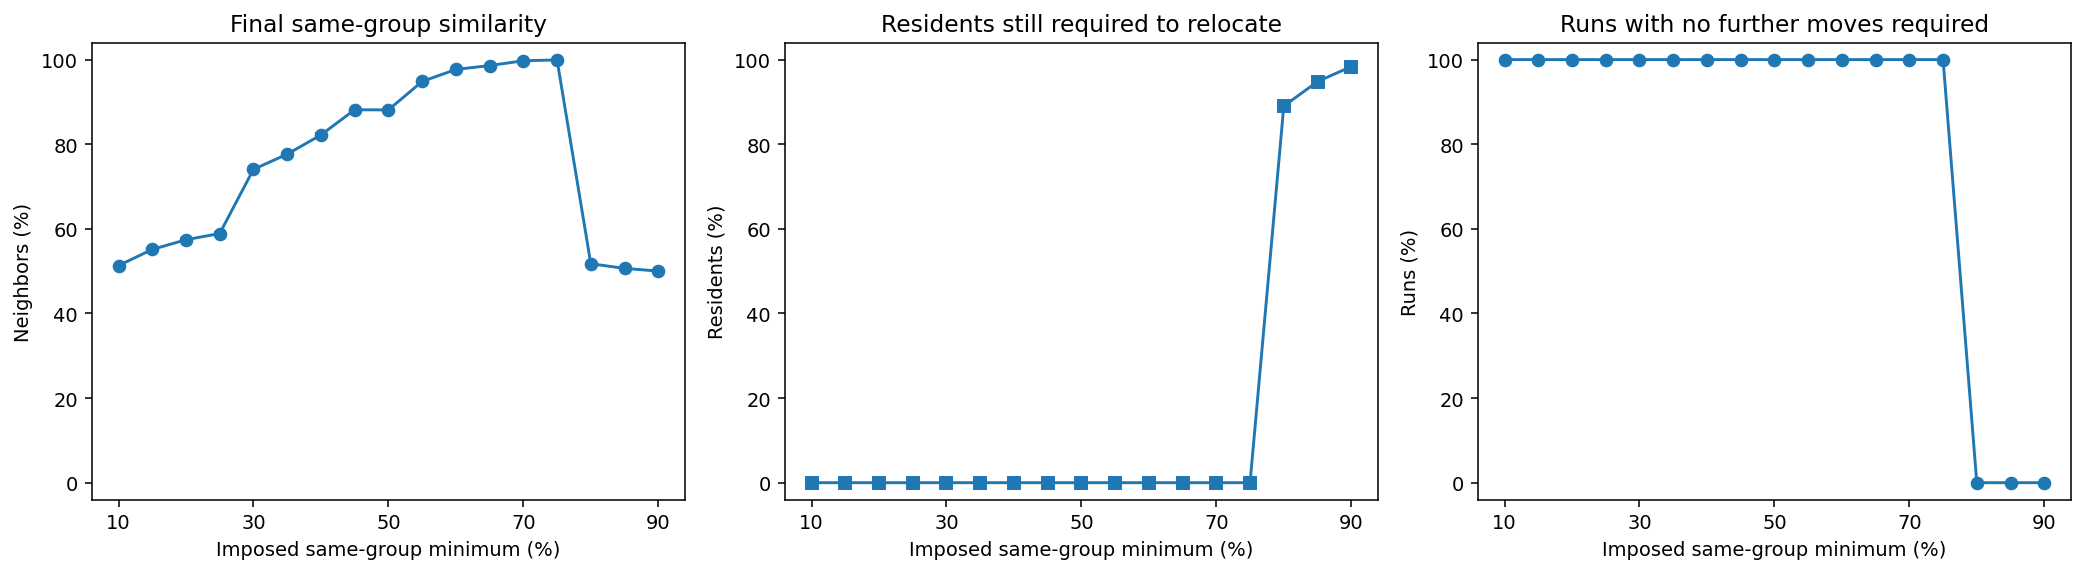

In [3]:
fig,axes=plt.subplots(1,3,figsize=(15,4.2))
axes[0].errorbar(classic.index,classic.similar_mean,yerr=classic.similar_ci_half,fmt='o-',capsize=3)
axes[0].set(title='Final same-group similarity',ylabel='Neighbors (%)')
axes[1].errorbar(classic.index,classic.relocate_mean,yerr=classic.relocate_ci_half,fmt='s-',capsize=3)
axes[1].set(title='Residents still required to relocate',ylabel='Residents (%)')
axes[2].plot(classic.index,classic.settled_pct,'o-')
axes[2].set(title='Runs with no further moves required',ylabel='Runs (%)')
for ax in axes:
    ax.set(xlabel='Imposed same-group minimum (%)',xticks=[10,30,50,70,90],ylim=(-4,104))
fig.tight_layout();plt.show()

## 4. How quickly does relocation stop?
Successful runs supply observed settling times. Nonsettled runs at 1,000 are censored: their eventual settling time is unknown. Do not average successful times alone and describe that as the speed of all runs. Median final ticks below summarize the observed endpoint, not necessarily time to an eventual event.

,count,median,min,max
minimum,,,,
10,30,2.0,1,4
15,30,5.0,3,11
20,30,6.0,4,9
25,30,7.0,5,10
30,30,12.0,9,26
35,30,12.0,9,22
40,30,14.5,11,19
45,30,17.5,13,28
50,30,16.0,13,31


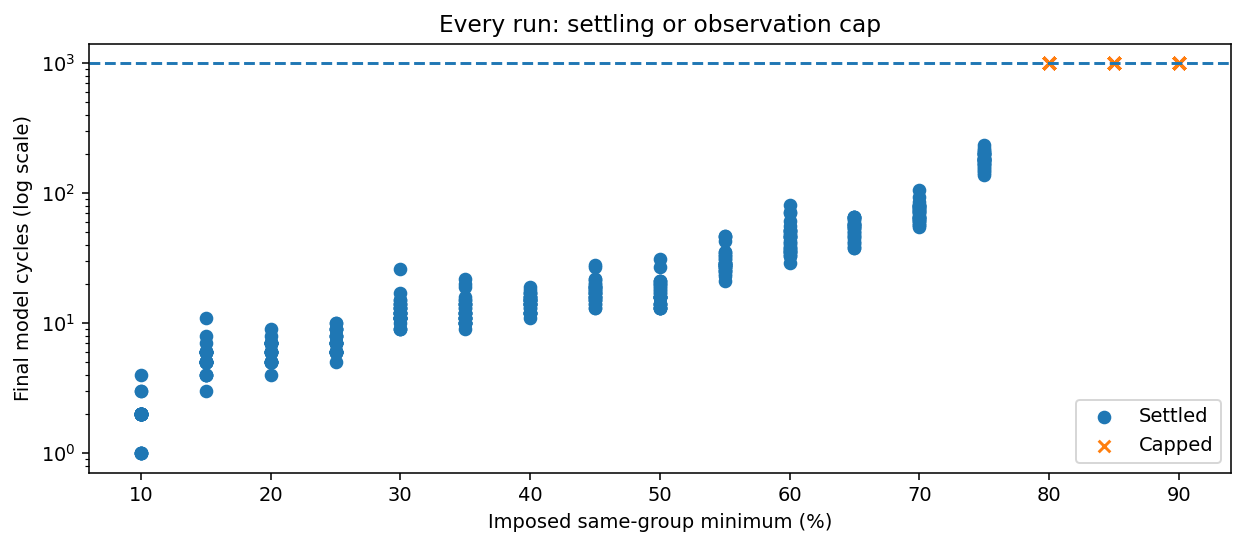

In [4]:
times=results[results.met].groupby('minimum').ticks.agg(['count','median','min','max'])
times
fig,ax=plt.subplots(figsize=(9,4))
for settled,marker,label in [(True,'o','Settled'),(False,'x','Capped')]:
    d=results[results.met==settled]
    ax.scatter(d.minimum,d.ticks,marker=marker,label=label)
ax.axhline(1000,linestyle='--')
ax.set(xlabel='Imposed same-group minimum (%)',ylabel='Final model cycles (log scale)',yscale='log',title='Every run: settling or observation cap')
ax.legend();fig.tight_layout();plt.show()

## 5. Decision-focused interpretation
The simulation tests whether imposing a local rule yields the intended residential pattern. It does not test enforcement, revolt, political stability, or the social costs of relocation.

## Policy interpretation
At the proposed 30% minimum, all 30 runs settle. Final same-group similarity averages 74.05%, with a between-run SD of 0.71 percentage points. Meeting the imposed requirement therefore does not ensure the mixing expected by the advisers.

The percentage summarizes local similarity. Notebook 2 uses locations and established spatial segregation indices to examine neighborhood separation. Runs reaching the cap remain unresolved; model cycles have no assigned calendar duration.

## Sources
[Course data and model](https://github.com/DACSS-Complexity/s6_From_Micromotives_to_Macrobehavior/tree/main/exercise): `policy-relocation-table.csv` and `Segregation_policy.nlogox`. Model lineage: Schelling (1969), Wilensky (1997), and course adaptation by Prof. Jose Magallanes. The uploaded model and analysis data must be versioned together for full reproducibility.